In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# Задание 1 — Подготовка данных

In [23]:
x = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
y = np.array([650, 800, 950, 1100, 1300, 1450, 1600, 1800, 1950, 2150])

n = len(x)

x, y

(array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10]),
 array([ 650,  800,  950, 1100, 1300, 1450, 1600, 1800, 1950, 2150]))

# Задание 2 — Математический расчёт линейной регрессии

In [24]:
sum_x = np.sum(x)
sum_y = np.sum(y)
sum_xy = np.sum(x * y)
sum_x2 = np.sum(x**2)

b = (n * sum_xy - sum_x * sum_y) / (n * sum_x2 - (sum_x) ** 2)

a = (sum_y - b * sum_x) / n

print(f"Математически рассчитанный коэффициент b (наклон): {b:.2f}")
print(f"Математически рассчитанный коэффициент a (свободный член): {a:.2f}")

print(f"\nУравнение регрессии: y = {b:.2f} * x + {a:.2f}")

Математически рассчитанный коэффициент b (наклон): 166.36
Математически рассчитанный коэффициент a (свободный член): 460.00

Уравнение регрессии: y = 166.36 * x + 460.00


### Коэффициент b показывает, на сколько в среднем увеличивается ежемесячная заработная плата сотрудника (в AZN) при увеличении его стажа работы на 1 год.

In [25]:
y_pred = b * x + a
np.round(y_pred, 2)

array([ 626.36,  792.73,  959.09, 1125.45, 1291.82, 1458.18, 1624.55,
       1790.91, 1957.27, 2123.64])

# Задание 3 — Построение модели с помощью Scikit-learn

In [26]:
X_reshaped = x.reshape(-1, 1)
model = LinearRegression()

model.fit(X_reshaped, y)

a_sklearn = model.intercept_
b_sklearn = model.coef_[0]

a_sklearn, b_sklearn

(np.float64(460.0000000000001), np.float64(166.36363636363635))

In [27]:
print(f"\nСравнение коэффициентов b: математический = {b:.4f}, sklearn = {b_sklearn:.4f}")
print(f"Сравнение коэффициентов a: математический = {a:.4f}, sklearn = {a_sklearn:.4f}")


Сравнение коэффициентов b: математический = 166.3636, sklearn = 166.3636
Сравнение коэффициентов a: математический = 460.0000, sklearn = 460.0000


### Результаты совпадают идеально (с точностью до машиннных погрешностей), потому что класс LinearRegression в Scikit-learn под капотом использует тот же самый метод наименьших квадратов (Ordinary Least Squares, OLS) для аналитического поиска оптимальных параметров минимизации среднеквадратичной ошибки (MSE).

# Задание 4 — Визуализация

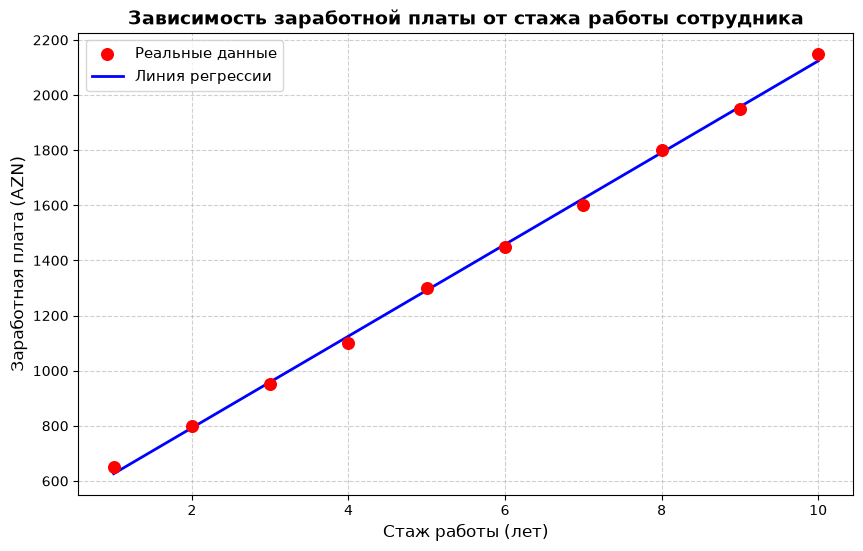

In [28]:
plt.figure(figsize=(10, 6))

plt.scatter(x, y, color="red", label="Реальные данные", s=70, zorder=5)

y_line = model.predict(X_reshaped)
plt.plot(x, y_line, color="blue", linewidth=2, label="Линия регрессии")

plt.xlabel("Стаж работы (лет)", fontsize=12)
plt.ylabel("Заработная плата (AZN)", fontsize=12)
plt.title(
    "Зависимость заработной платы от стажа работы сотрудника",
    fontsize=14,
    weight="bold",
)

plt.legend(fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)

plt.show()

# Задание 5 — Получение новых прогнозов

In [29]:
new_experience = np.array([2.5, 4.5, 7.5, 12]).reshape(-1, 1)
new_predictions = model.predict(new_experience)

for exp, pred in zip(new_experience.flatten(), new_predictions):
    print(f"Стаж: {exp} лет —> Прогноз: {pred:.2f} AZN")

Стаж: 2.5 лет —> Прогноз: 875.91 AZN
Стаж: 4.5 лет —> Прогноз: 1208.64 AZN
Стаж: 7.5 лет —> Прогноз: 1707.73 AZN
Стаж: 12.0 лет —> Прогноз: 2456.36 AZN


In [30]:
print("Введите стаж работы для расчета (введите 0 для выхода):\n")

while True:
    user_input = input("Введите стаж работы (лет): ").strip()

    if user_input == "0":
        print("Программа завершена. До свидания!")
        break

    try:
        exp_value = float(user_input)
    except ValueError:
        print(
            "Ошибка: Пожалуйста, введите корректное числовое значение стажа.\n"
        )
        continue

    if exp_value < 0:
        print("Ошибка: Стаж работы не может быть отрицательным числом.\n")
        continue

    predicted_salary = model.predict(np.array([[exp_value]])) [0]
    print(
        f"--> Прогнозируемая заработная плата для стажа {exp_value} лет: {predicted_salary:.2f} AZN\n"
    )

Введите стаж работы для расчета (введите 0 для выхода):

--> Прогнозируемая заработная плата для стажа 15.0 лет: 2955.45 AZN

--> Прогнозируемая заработная плата для стажа 10.0 лет: 2123.64 AZN

Ошибка: Пожалуйста, введите корректное числовое значение стажа.

--> Прогнозируемая заработная плата для стажа 7.0 лет: 1624.55 AZN

Программа завершена. До свидания!


### Ответы на аналитические вопросы:

**1. Для чего используется линейная регрессия?**
Линейная регрессия используется для моделирования и исследования линейной зависимости между одной или несколькими независимыми переменными (признаками, $x$) и зависимой переменной ($y$). Она применяется для задач прогнозирования (регрессии), когда требуется оценить непрерывное целевое значение на основе входных данных.

**2. Что делают методы fit() и predict()?**
* `fit(X, y)` — обучает модель. На основе переданных тренировочных данных алгоритм находит оптимальные веса (коэффициенты модели), минимизируя ошибку прогноза (в случае линейной регрессии — методом наименьших квадратов).
* `predict(X)` — использует уже обученную модель для вычисления и выдачи прогнозируемых значений целевой переменной ($y$) для новых переданных входных данных ($X$).

**3. В чём разница между coef_ и intercept_?**
* `coef_` — это коэффициент наклона (slope, или $b$ в уравнении $y = bx + a$). Он определяет угол наклона линии регрессии и показывает скорость изменения целевой переменной при изменении признака на единицу.
* `intercept_` — это свободный член (смещение, или $a$), который определяет точку пересечения линии регрессии с вертикальной осью $Y$ (когда значение признака $x = 0$).

**4. Почему к прогнозу для 12 лет стажа работы следует относиться с осторожностью?**
Этот прогноз является **экстраполяцией** — то есть оценкой за пределами диапазона исходных данных, на которых обучалась модель (в исходном датасет максимальный стаж составлял 10 лет). Модель линейной регрессии предполагает сохранение строгой линейной зависимости бесконечно далеко, однако в реальности рост зарплаты со стажем может замедляться (выходить на плато) или, наоборот, резко возрастать после определенного порога квалификации (senior-уровня). Без дополнительных данных за пределами 10 лет доверять такому прогнозу рискованно.

**5. Достаточно ли использовать только стаж работы для прогнозирования заработной платы? Обоснуйте свой ответ.**
Нет, исключительно стажа работы недостаточно для точного и надежного прогнозирования заработной платы. На уровень дохода сотрудника влияет огромное количество других скрытых факторов:
* Уровень квалификации / стек технологий (hard skills).
* Должность и зона ответственности (Junior, Middle, Senior, Team Lead).
* Размер компании, форма собственности и её географическое расположение.
* Эффективность работы, наличие успешных завершенных проектов и сертификаций.
Использование только одного признака ($x$) приводит к высокой степени упрощения (недообучению сложной бизнес-реальности), поэтому в реальных задачах применяют *множественную линейную регрессию*, учитывающую сразу множество параметров.